In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

df = pd.read_csv("data/segmentation_data.csv")

In [23]:
if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

sex_mapping = {0: 'Мужчина', 1: 'Женщина'}
marital_mapping = {0: 'Не в браке', 1: 'В браке'}
education_mapping = {0: 'Без образования', 1: 'Школа', 2: 'Колледж', 3: 'Бакалавр', 4: 'Магистр'}
occupation_mapping = {0: 'Безработный', 1: 'Работает'}
settlement_mapping = {0: 'Сельская местность', 1: 'Пригород', 2: 'Город'}

df_interpret = df.copy()
df_interpret['Пол'] = df_interpret['Sex'].map(sex_mapping)
df_interpret['Семейное_положение'] = df_interpret['Marital status'].map(marital_mapping)
df_interpret['Образование'] = df_interpret['Education'].map(education_mapping)
df_interpret['Занятость'] = df_interpret['Occupation'].map(occupation_mapping)
df_interpret['Тип_поселения'] = df_interpret['Settlement size'].map(settlement_mapping)

In [24]:
feature_cols = ['Age', 'Income', 'Education', 'Occupation', 'Settlement size']
X = df[feature_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

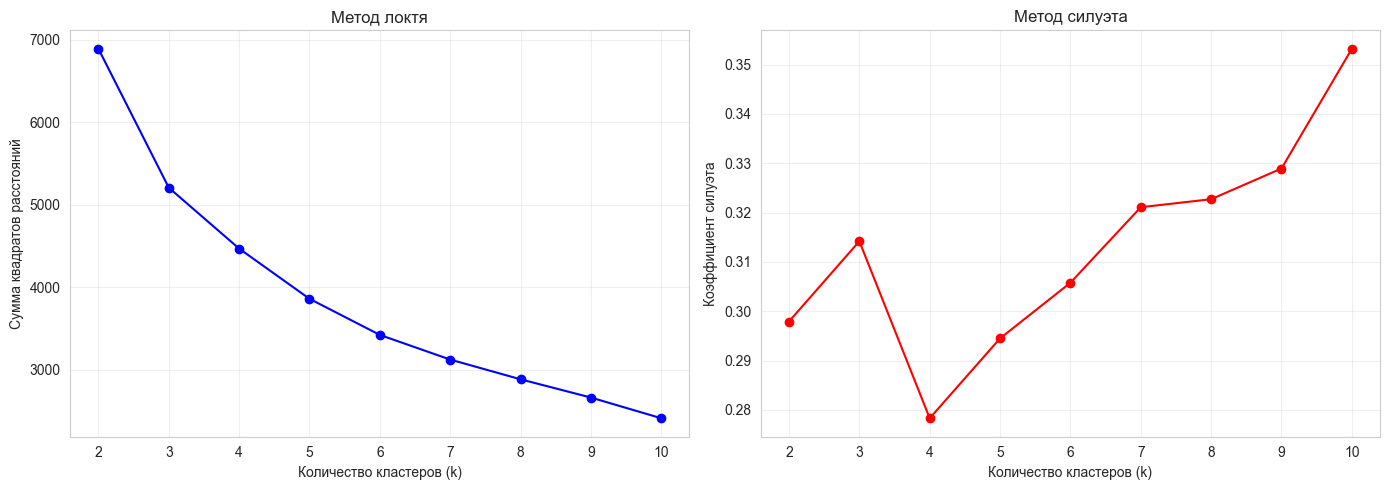

Оптимальное количество кластеров: 10


In [25]:
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_xlabel('Количество кластеров (k)')
axes[0].set_ylabel('Сумма квадратов расстояний')
axes[0].set_title('Метод локтя') # иронично что я пишу код как раз после операции в области локтя, так уж и быть без кровавых подробностей
axes[0].grid(True, alpha=0.3)

axes[1].plot(K_range, silhouette_scores, 'ro-')
axes[1].set_xlabel('Количество кластеров (k)')
axes[1].set_ylabel('Коэффициент силуэта')
axes[1].set_title('Метод силуэта')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_k = K_range[np.argmax(silhouette_scores)]
print(f"Оптимальное количество кластеров: {best_k}")

In [26]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans.fit(X_scaled)

df['Cluster'] = kmeans.labels_
df_interpret['Cluster'] = kmeans.labels_

print("Распределение по кластерам:")
print(df['Cluster'].value_counts().sort_index())

cluster_centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
cluster_centers_df = pd.DataFrame(
    cluster_centers_original,
    columns=feature_cols,
    index=[f'Кластер {i}' for i in range(best_k)]
)
print("\nЦентры кластеров:")
print(cluster_centers_df.round(2))

Распределение по кластерам:
Cluster
0    304
1    140
2    412
3    349
4    153
5    133
6    137
7     80
8    179
9    113
Name: count, dtype: int64

Центры кластеров:
             Age     Income  Education  Occupation  Settlement size
Кластер 0  30.93  116382.67       0.99        1.01             0.00
Кластер 1  55.66  143019.07       2.14        0.91             1.24
Кластер 2  32.70   87140.45       1.00        0.00             0.03
Кластер 3  28.84  116507.26       1.00        1.00             1.42
Кластер 4  35.52  171131.99       0.91        1.98             1.52
Кластер 5  27.05   89295.89      -0.00        0.33            -0.00
Кластер 6  27.50  130196.86      -0.00        1.07             1.53
Кластер 7  54.85  207985.48       2.10        1.95             1.49
Кластер 8  44.85  141891.02       1.00        0.96             1.31
Кластер 9  51.96  106275.12       2.02        0.15             0.01


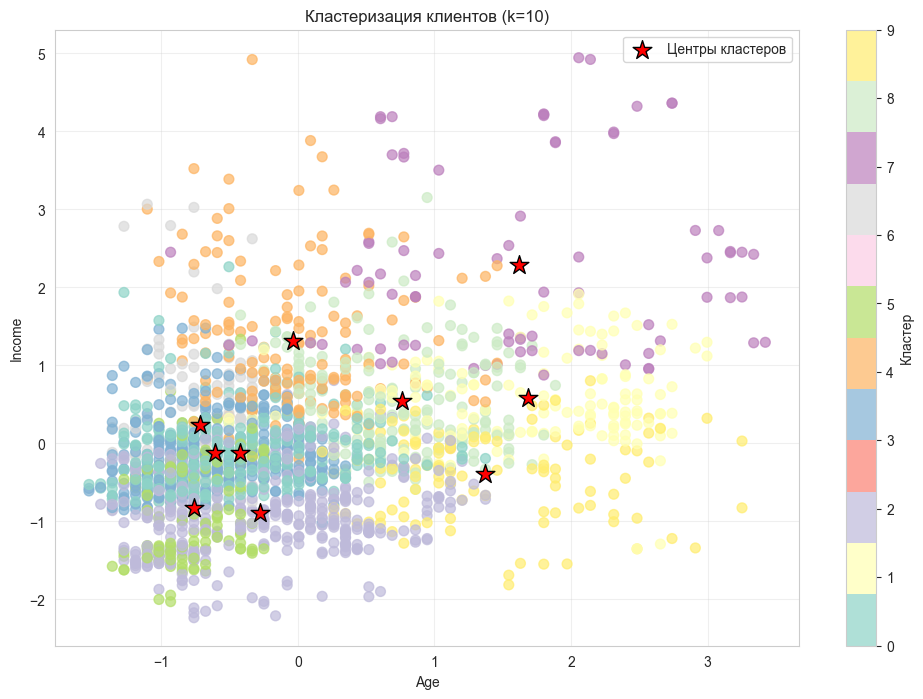

In [27]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
                      c=kmeans.labels_, cmap='Set3', s=50, alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=200, c='red', marker='*', edgecolors='black', label='Центры кластеров')
plt.xlabel(feature_cols[0])
plt.ylabel(feature_cols[1])
plt.title(f'Кластеризация клиентов (k={best_k})')
plt.colorbar(scatter, label='Кластер')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

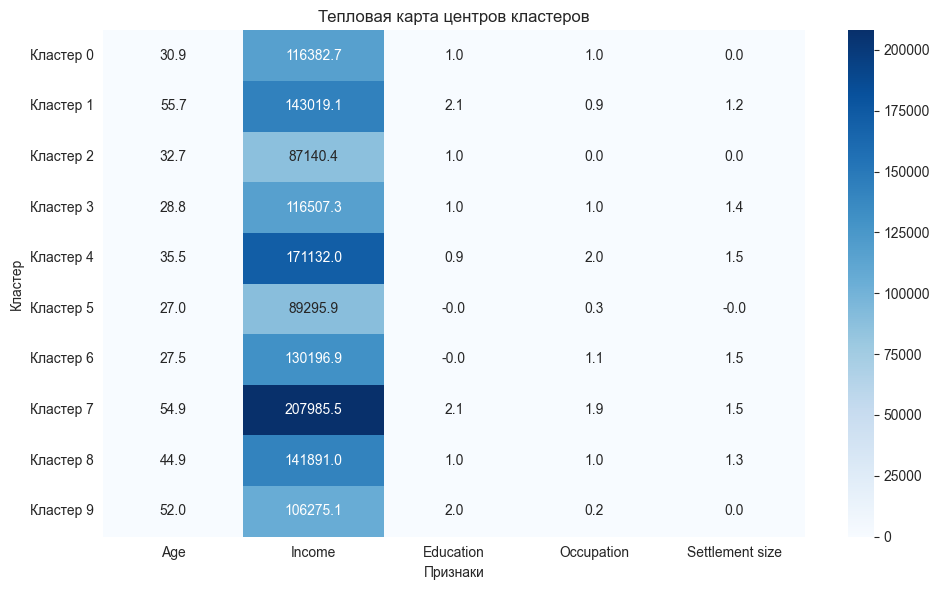

In [28]:
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_centers_df, annot=True, cmap='Blues', fmt='.1f')
plt.title('Тепловая карта центров кластеров')
plt.xlabel('Признаки')
plt.ylabel('Кластер')
plt.tight_layout()
plt.show()

In [29]:
cluster_profile = df.groupby('Cluster')[feature_cols].agg(['mean', 'median']).round(2)
print("Числовые характеристики кластеров:")
print(cluster_profile)

Числовые характеристики кластеров:
           Age            Income           Education        Occupation         \
          mean median       mean    median      mean median       mean median   
Cluster                                                                         
0        30.93   30.0  116382.67  112977.0      0.99    1.0       1.01    1.0   
1        55.66   58.0  143019.07  138485.5      2.14    2.0       0.91    1.0   
2        32.70   33.0   87140.45   85994.5      1.00    1.0       0.00    0.0   
3        28.84   28.0  116507.26  113004.0      1.00    1.0       1.00    1.0   
4        35.52   35.0  171131.99  161323.0      0.91    1.0       1.98    2.0   
5        27.05   27.0   89295.89   84531.0      0.00    0.0       0.33    0.0   
6        27.50   27.0  130196.86  126060.0      0.00    0.0       1.07    1.0   
7        54.85   55.0  207985.48  197268.0      2.10    2.0       1.95    2.0   
8        44.85   45.0  141891.02  137069.0      1.00    1.0       0.96    

In [30]:
for cluster in sorted(df['Cluster'].unique()):
    print(f"Кластер {cluster} (размер: {len(df[df['Cluster']==cluster])} клиентов)")

    cluster_data = df_interpret[df_interpret['Cluster'] == cluster]

    print("\nПол:")
    print(cluster_data['Пол'].value_counts(normalize=True).round(2))
    print("\nСемейное положение:")
    print(cluster_data['Семейное_положение'].value_counts(normalize=True).round(2))
    print("\nОбразование:")
    print(cluster_data['Образование'].value_counts(normalize=True).round(2))
    print("\nЗанятость:")
    print(cluster_data['Занятость'].value_counts(normalize=True).round(2))
    print("\nТип поселения:")
    print(cluster_data['Тип_поселения'].value_counts(normalize=True).round(2))

Кластер 0 (размер: 304 клиентов)

Пол:
Пол
Женщина    0.67
Мужчина    0.33
Name: proportion, dtype: float64

Семейное положение:
Семейное_положение
В браке       0.67
Не в браке    0.33
Name: proportion, dtype: float64

Образование:
Образование
Школа              0.99
Без образования    0.01
Name: proportion, dtype: float64

Занятость:
Занятость
Работает       0.99
Безработный    0.01
Name: proportion, dtype: float64

Тип поселения:
Тип_поселения
Сельская местность    1.0
Name: proportion, dtype: float64
Кластер 1 (размер: 140 клиентов)

Пол:
Пол
Мужчина    0.51
Женщина    0.49
Name: proportion, dtype: float64

Семейное положение:
Семейное_положение
В браке       0.71
Не в браке    0.29
Name: proportion, dtype: float64

Образование:
Образование
Колледж     0.86
Бакалавр    0.14
Name: proportion, dtype: float64

Занятость:
Занятость
Работает       0.91
Безработный    0.09
Name: proportion, dtype: float64

Тип поселения:
Тип_поселения
Пригород              0.50
Город                 0.37

In [31]:
for cluster in sorted(df['Cluster'].unique()):
    size = len(df[df['Cluster'] == cluster])
    percent = size / len(df) * 100
    print(f"\nКластер {cluster} ({size} клиентов, {percent:.1f}%)")

    cluster_num = df[df['Cluster'] == cluster]
    cluster_cat = df_interpret[df_interpret['Cluster'] == cluster]

    desc = []
    income_mean = cluster_num['Income'].mean()
    overall_income = df['Income'].mean()
    if income_mean > overall_income * 1.2:
        desc.append("высокий доход")
    elif income_mean < overall_income * 0.8:
        desc.append("низкий доход")
    else:
        desc.append("средний доход")

    age_mean = cluster_num['Age'].mean()
    overall_age = df['Age'].mean()
    if age_mean > overall_age * 1.1:
        desc.append("старшая возрастная группа")
    elif age_mean < overall_age * 0.9:
        desc.append("младшая возрастная группа")
    else:
        desc.append("средний возраст")

    sex_dist = cluster_cat['Пол'].value_counts(normalize=True)
    if len(sex_dist) > 0 and sex_dist.iloc[0] > 0.6:
        desc.append(f"преимущественно {sex_dist.idxmax().lower()}")

    marital_dist = cluster_cat['Семейное_положение'].value_counts(normalize=True)
    if len(marital_dist) > 0 and marital_dist.iloc[0] > 0.6:
        desc.append(f"преимущественно {marital_dist.idxmax().lower()}")

    sett_dist = cluster_cat['Тип_поселения'].value_counts(normalize=True)
    if len(sett_dist) > 0 and sett_dist.iloc[0] > 0.6:
        desc.append(f"проживают в {sett_dist.idxmax().lower()}")

    print(f"Характеристики: {', '.join(desc)}")


Кластер 0 (304 клиентов, 15.2%)
Характеристики: средний доход, младшая возрастная группа, преимущественно женщина, преимущественно в браке, проживают в сельская местность

Кластер 1 (140 клиентов, 7.0%)
Характеристики: средний доход, старшая возрастная группа, преимущественно в браке

Кластер 2 (412 клиентов, 20.6%)
Характеристики: низкий доход, средний возраст, преимущественно женщина, проживают в сельская местность

Кластер 3 (349 клиентов, 17.4%)
Характеристики: средний доход, младшая возрастная группа, преимущественно в браке

Кластер 4 (153 клиентов, 7.6%)
Характеристики: высокий доход, средний возраст, преимущественно мужчина, преимущественно не в браке

Кластер 5 (133 клиентов, 6.7%)
Характеристики: низкий доход, младшая возрастная группа, преимущественно мужчина, преимущественно не в браке, проживают в сельская местность

Кластер 6 (137 клиентов, 6.9%)
Характеристики: средний доход, младшая возрастная группа, преимущественно мужчина, преимущественно не в браке

Кластер 7 (80 к